# Timing analysis

Loads the `*_timing.csv` files produced by `hcc.py` (one per run, alongside its `output_file`) and shows, per dataset, the distribution of the time (in minutes) spent on:

- `t_covers`: constructing the covers
- `t_propagate`: propagating scores up the taxonomy for calib + test sets
- `t_calibration`: calibrating the scores
- `t_optimization`: optimizing the mm
- `t_total`: total run time

In [1]:
import glob
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
TIME_COLUMNS = ['t_covers', 't_propagate', 't_calibration', 't_optimization', 't_total']


def format_dataset(path: str) -> str:
    """Maps a timing file path to its dataset name."""
    if 'gtzan' in path:
        return 'gtzan'
    if 'dbpedia' in path:
        return 'dbpedia14'
    if 'imagenet' in path:
        return 'imagenet'
    return 'unknown'

## Discover and load timing files

Every run of `hcc.py` writes a `..._timing.csv` next to its `output_file` (e.g. `hcp_0.1_0.25_first.csv` -> `hcp_0.1_0.25_first_timing.csv`). We glob for all of them under `data/`.

In [3]:
timing_files = sorted(glob.glob('data/*/*_timing.csv'))
timing_files

['data/dbpedia14/hcp_0.0003_0.19_first_timing.csv',
 'data/gtzan/hcp_0.1_0.25_first_timing.csv']

In [4]:
frames = []
for f in timing_files:
    df = pd.read_csv(f)
    df['dataset'] = format_dataset(f)
    df['run'] = f
    frames.append(df)
timing_df = pd.concat(frames, ignore_index=True) if frames else pd.DataFrame(columns=TIME_COLUMNS + ['dataset', 'run'])
timing_df[TIME_COLUMNS] = timing_df[TIME_COLUMNS] / 60  # seconds -> minutes
timing_df.head()

,alpha,bf_alpha,beta,t_covers,t_propagate,t_calibration,t_optimization,t_total,dataset,run
0,0.0003,0.0003,0.19,0.016205,0.036302,0.422003,138.238522,138.725351,dbpedia14,data/dbpedia14/hcp_0.0003_0.19_first_timing.csv
1,0.1000,0.1000,0.25,0.000585,0.003719,0.001609,0.169338,0.177353,gtzan,data/gtzan/hcp_0.1_0.25_first_timing.csv


## Distribution per dataset

Summary statistics (count, mean, std, min, quartiles, max) for each timing column, grouped by dataset.

In [5]:
timing_df.groupby('dataset')[TIME_COLUMNS].describe().T

dataset                dbpedia14     gtzan
t_covers       count    1.000000  1.000000
               mean     0.016205  0.000585
               std           NaN       NaN
               min      0.016205  0.000585
               25%      0.016205  0.000585
               50%      0.016205  0.000585
               75%      0.016205  0.000585
               max      0.016205  0.000585
t_propagate    count    1.000000  1.000000
               mean     0.036302  0.003719
               std           NaN       NaN
               min      0.036302  0.003719
               25%      0.036302  0.003719
               50%      0.036302  0.003719
               75%      0.036302  0.003719
               max      0.036302  0.003719
t_calibration  count    1.000000  1.000000
               mean     0.422003  0.001609
               std           NaN       NaN
               min      0.422003  0.001609
               25%      0.422003  0.001609
               50%      0.422003  0.001609
               75%      0.422003  0.001609
               max      0.422003  0.001609
t_optimization count    1.000000  1.000000
               mean   138.238522  0.169338
               std           NaN       NaN
               min    138.238522  0.169338
               25%    138.238522  0.169338
               50%    138.238522  0.169338
               75%    138.238522  0.169338
               max    138.238522  0.169338
t_total        count    1.000000  1.000000
               mean   138.725351  0.177353
               std           NaN       NaN
               min    138.725351  0.177353
               25%    138.725351  0.177353
               50%    138.725351  0.177353
               75%    138.725351  0.177353
               max    138.725351  0.177353

## Boxplots per dataset

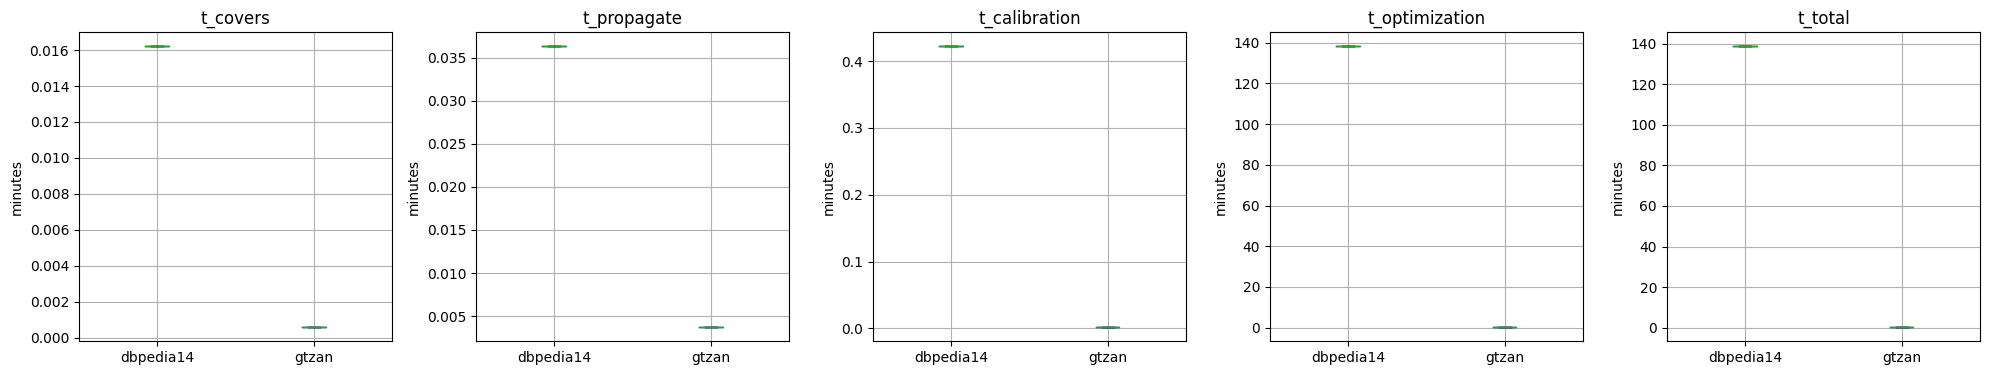

In [6]:
fig, axes = plt.subplots(1, len(TIME_COLUMNS), figsize=(4 * len(TIME_COLUMNS), 4), sharey=False)
for ax, col in zip(axes, TIME_COLUMNS):
    timing_df.boxplot(column=col, by='dataset', ax=ax)
    ax.set_title(col)
    ax.set_xlabel('')
    ax.set_ylabel('minutes')
plt.suptitle('')
plt.tight_layout()
plt.show()

## Runtime per item

Each `..._timing.csv` file corresponds to an output file with one row per test item (e.g. `hcp_0.1_0.25_first_timing.csv` -> `hcp_0.1_0.25_first.csv`). We count the rows in that output file and divide the (seconds) timing values by it to get a per-item runtime, then report the mean and standard deviation per dataset.

In [7]:
import os


def output_file_for_timing(timing_path: str) -> str:
    """Maps a `..._timing.csv` path back to the corresponding output file."""
    base, ext = os.path.splitext(timing_path)
    assert base.endswith('_timing'), f'unexpected timing file name: {timing_path}'
    return base[:-len('_timing')] + ext


n_items = {f: len(pd.read_csv(output_file_for_timing(f))) for f in timing_files}
timing_df['n_items'] = timing_df['run'].map(n_items)
timing_df[['run', 'dataset', 'n_items']].drop_duplicates()

,run,dataset,n_items
0,data/dbpedia14/hcp_0.0003_0.19_first_timing.csv,dbpedia14,56000
1,data/gtzan/hcp_0.1_0.25_first_timing.csv,gtzan,800


In [8]:
PER_ITEM_COLUMNS = [f'{col}_per_item_s' for col in TIME_COLUMNS]
# timing_df's TIME_COLUMNS are in minutes; convert back to seconds before dividing by item count
timing_df[PER_ITEM_COLUMNS] = timing_df[TIME_COLUMNS].mul(60).div(timing_df['n_items'], axis=0)

timing_df.groupby('dataset')[PER_ITEM_COLUMNS].agg(['mean', 'std']).T

dataset                         dbpedia14     gtzan
t_covers_per_item_s       mean   0.000017  0.000044
                          std         NaN       NaN
t_propagate_per_item_s    mean   0.000039  0.000279
                          std         NaN       NaN
t_calibration_per_item_s  mean   0.000452  0.000121
                          std         NaN       NaN
t_optimization_per_item_s mean   0.148113  0.012700
                          std         NaN       NaN
t_total_per_item_s        mean   0.148634  0.013301
                          std         NaN       NaN

In [11]:
0.188059858 * 800

150.4478864

In [12]:
2.55525 * 56000

143094.0

In [15]:
0.171076029 * 800

136.8608232